# 03. ノートブックでの定量データチャート描画

<p><a href="https://colab.research.google.com/github/yuichi110/drawlib/blob/main/docs/jupyter/ja/03_data_charts.ipynb" target="_blank" rel="noopener noreferrer"></a></p>

Drawlib には 10 種類の定量チャート（`BarChart`、`LineChart`、`AreaChart`、`PieChart`、`RadarChart`、`BoxChart`、`ScatterChart`、`GanttChart`、`HeatmapChart`、`HeatmapOverlay`）が用意されており、カードや注釈と同一キャンバス上に配置できます。

<p align="center">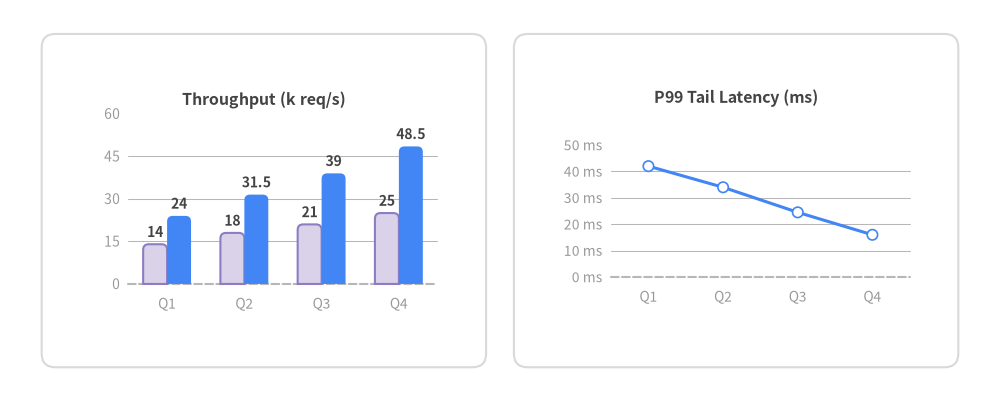</p>

<p align="center"><em>1 つのキャンバス上に複数チャートを配置したダッシュボード</em></p>

In [ ]:
!pip install -q drawlib

---

## 1. Python セルでメトリクスを集計する

ノートブックのセル間で変数が共有されるため、まず Python コードで生データを集計してから Drawlib のチャートに渡すことができます。

In [ ]:
raw_latencies_ms = {
    "v0.3.8": [48.2, 46.0, 49.5, 45.1],
    "v0.3.9": [34.0, 32.5, 35.1, 31.8],
    "v0.3.10": [22.4, 21.0, 23.1, 20.5],
    "v0.3.11": [15.8, 14.9, 16.2, 14.5],
}

releases = list(raw_latencies_ms.keys())
mean_latencies = [round(sum(vals) / len(vals), 1) for vals in raw_latencies_ms.values()]
for rel, avg in zip(releases, mean_latencies, strict=True):
    print(f"{rel}: mean={avg:.1f} ms")
mean_latencies

---

## 2. 集計結果とサマリカードの組み合わせ描画

すべての `Charts` コンポーネントは **左下座標 `(x0, y0)`** を基準に配置します。

In [ ]:
from drawlib.canvas import show, setup
from drawlib.charts.bar import BarChart
from drawlib.shapes import rectangle
from drawlib.styles import Styles
from drawlib.text import text

setup(width=120, height=44, cwd=True)

chart = BarChart(
    axis_line_style=Styles.MutedDashed,
    categories=releases,
    width=66.0,
    height=30.0,
    bar_width_ratio=0.58,
    bar_r=0.8,
    axis_text_style=Styles.Muted.patch(text_size=10.0),
    grid_style=Styles.MutedThin,
    value_text_style=Styles.DarkBold.patch(text_size=10.0),
    value_format="{:.1f}",
    title="Mean Rendering Latency by Release (ms)",
    title_style=Styles.DarkBold.patch(text_size=11.5),
)
chart.add_series("Mean Latency", mean_latencies, style=Styles.PrimaryFlat)
chart.configure_y_axis(min_value=0.0, max_value=60.0, tick_step=15.0)
chart.draw(xy=(8.0, 8.0))

# Summary Callout Card on the Right (Center Anchor)
rectangle((97.0, 23.0), width=32.0, height=24.0, style=Styles.PrimaryFlat.patch(shape_r=2.0))
text((97.0, 29.5), "68% Faster", style=Styles.WhiteBold.patch(text_size=13))
text((97.0, 23.0), "v0.3.8 -> v0.3.11", style=Styles.White.patch(text_size=10.5))
text((97.0, 16.5), "15.4 ms avg", style=Styles.WhiteBold.patch(text_size=11))

show()